In [3]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.datasets import load_wine
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.neighbors import KNeighborsClassifier
from sklearn.naive_bayes import GaussianNB
from sklearn.metrics import accuracy_score

In [4]:
data = load_wine(as_frame=True)
X, y = data.data, data.target
X_train,X_test,y_train,y_test = train_test_split(X,y,
                                                 test_size=0.2,random_state=42,stratify=y)

In [6]:
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)
# Catatan : Naive Bayes tidak memerlukan scaling namun KNN sangat sensitif terhadap skala fitur

In [8]:
knn = KNeighborsClassifier(n_neighbors=5,
                           weights="distance")
knn.fit(X_train_scaled, y_train)

nb = GaussianNB()
nb.fit(X_train, y_train)

,priors,None
,var_smoothing,1e-09


In [9]:
acc_knn = accuracy_score(y_test,knn.predict(X_test_scaled))
acc_nb = accuracy_score(y_test, nb.predict(X_test))
print(f"Akurasi KNN (k=5, weighted): {acc_knn:.3f}")
print(f"Akurasi Gaussian Naive Bayes; {acc_nb:.3f}")

Akurasi KNN (k=5, weighted): 0.972
Akurasi Gaussian Naive Bayes; 0.972


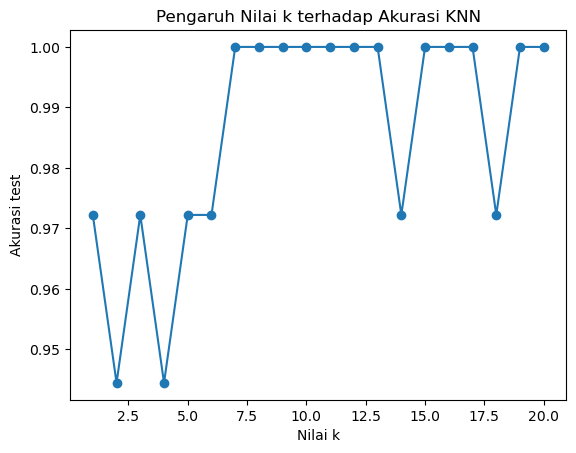

In [17]:
akurasi_k = []
nilai_k = range(1, 21)
for k in nilai_k:
    model = KNeighborsClassifier(n_neighbors=k).fit(X_train_scaled, y_train) 
    akurasi_k.append(accuracy_score(y_test, model.predict(X_test_scaled)))
plt.plot(nilai_k, akurasi_k,marker='o')
plt.xlabel("Nilai k");
plt.ylabel("Akurasi test")
plt.title("Pengaruh Nilai k terhadap Akurasi KNN")
plt.show()